In [1]:
# Préparation
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
CUDA disponible: False


In [2]:
# Tensors
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0,2.0,3.0])
matrix = torch.tensor([[1.0,2.0],[3.0,4.0]])

print("scalar:",scalar,"shape = ",scalar.shape)
print("vector:",vector,"shape = ",vector.shape)
print("matrix:",matrix, "shape = ", matrix.shape)
print("dtype: ", matrix.dtype)
print("ndim:", matrix.ndim)

scalar: tensor(3.) shape =  torch.Size([])
vector: tensor([1., 2., 3.]) shape =  torch.Size([3])
matrix: tensor([[1., 2.],
        [3., 4.]]) shape =  torch.Size([2, 2])
dtype:  torch.float32
ndim: 2


In [3]:
# Opération sur les tenseurs
x = torch.arange(12)
print("x=",x)

x2=x.reshape(3,4)
print("reshape(3,4):",x2)

print("colonne 1: ", x2[:,1])
print("ligne 0: ", x2[0,:])

A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[2., 0.], [1.,2.]])
print("A @ B = ", A@B)

print("mean(A)=", A.mean())
print("sum(A)=", A.sum())

x= tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
reshape(3,4): tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
colonne 1:  tensor([1, 5, 9])
ligne 0:  tensor([0, 1, 2, 3])
A @ B =  tensor([[ 4.,  4.],
        [10.,  8.]])
mean(A)= tensor(2.5000)
sum(A)= tensor(10.)


In [4]:
#CPU, GPU et Devide
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé:", device)

x = torch.tensor([1.0, 2.0, 3.0]).to(device)
print("x.device =", x.device)

Device utilisé: cpu
x.device = cpu


In [8]:
# Autograd
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad = True)
b = torch.tensor(1.0, requires_grad = True)
y = w * x + b
loss = (y - 10) ** 2
# 10 est sûrement le label réel de 2.0


In [6]:
loss.backward()
print("y = ", y.item())
print("loss = ", loss.item())
print("dLoss/dw = ", w.grad.item())
print("dLoss/db = ", b.grad.item())

y =  7.0
loss =  9.0
dLoss/dw =  -12.0
dLoss/db =  -6.0


In [9]:
#Une autre façon de faire
#executer la cellude "Autograd en premier"
dw, db = torch.autograd.grad(loss, (w, b))
print("y = ", y.item())
print("loss = ", loss.item())
print("dLoss/dw = ", dw.item())
print("dLoss/db = ", db.item())

y =  7.0
loss =  9.0
dLoss/dw =  -12.0
dLoss/db =  -6.0


In [10]:
# Vérification analytique
'''
y = wx + b

L = (y - 10)²
L = (wx + b - 10)²
dL/dw = 2 d(wx + b - 10)/dw (wx + b - 10)
dL/dw = 2(y - 10)x
dL/db = 2 d(wx + b - 10)/db (wx + b - 10)
dL/db = 2(y - 10)
'''
y_val = (3.0 * 2.0 + 1.0)
dL_dw = 2 * (y_val - 10) * 2.0
dL_db = 2 * (y_val - 10)
print(dL_dw, dL_db)

-12.0 -6.0


In [ ]:
# Un neuron avec nn.Linear
# z = (sigma wi xi )+ b
import torch
import torch.nn as nn
from torchviz import make_dot
model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)
print("Sortie: ", y)
print("Poids: ", model.weight)
print("Biais: ", model.bias)
dot = make_dot(y, params=dict(model.named_parameters()))
dot.render("graphe_operations", format="png", cleanup=True)

Sortie:  tensor([[-1.0079]], grad_fn=<AddmmBackward0>)
Poids:  Parameter containing:
tensor([[-0.0460, -0.3510, -0.0432]], requires_grad=True)
Biais:  Parameter containing:
tensor([-0.1301], requires_grad=True)


'graphe_operations.png'

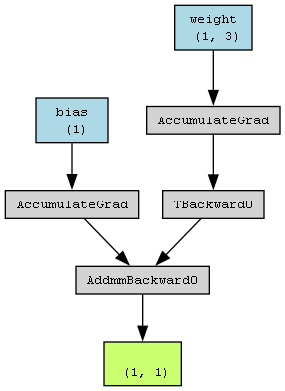

In [15]:
from IPython.display import Image, display
display(Image(filename="graphe_operations.png"))

In [ ]:
# Construire un réseau de neurones
class MLP(nn.Module)
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )
    def forward(self):
        return self.net(x)
model = MLP()
print(model)